In [1]:
# Telecom Customer Churn Prediction
# Project Notebook

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Project paths
BASE_DIR = Path.cwd()

if not (BASE_DIR / "telecom_churn_raw.csv").exists():
    BASE_DIR = Path.cwd().parent

RAW_FILE = BASE_DIR / "telecom_churn_raw.csv"
CLEAN_FILE = BASE_DIR / "telecom_churn_clean.csv"
REPORTS_DIR = BASE_DIR / "reports"
PLOTS_DIR = REPORTS_DIR / "plots"
MODELS_DIR = BASE_DIR / "models"

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Project directory:", BASE_DIR)
print("Raw dataset exists:", RAW_FILE.exists())
print("Cleaned dataset exists:", CLEAN_FILE.exists())
print("Reports directory exists:", REPORTS_DIR.exists())

Project directory: c:\Users\rabya\OneDrive\Documents\telecom-churn-prediction
Raw dataset exists: True
Cleaned dataset exists: True
Reports directory exists: True


In [2]:

# REQUIREMENT 1: Load and inspect the raw dataset

df_raw = pd.read_csv(RAW_FILE)

print("Dataset shape (rows, columns):")
print(df_raw.shape)

print("\nFirst 5 rows:")
display(df_raw.head())

print("\nColumn data types:")
display(df_raw.dtypes.to_frame(name="Data Type"))

print("\nDataset information:")
df_raw.info()

print("\nDescriptive statistics:")
display(df_raw.describe(include="all").T)


Dataset shape (rows, columns):
(1300, 23)

First 5 rows:


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,No,NaN,No,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,No
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,Yes,No,No,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,Yes
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,No internet service,No internet service,No internet service,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,No
3,TC-10362,Female,0,Yes,No,NaN,2023-07-02,yes,Yes,FIBER OPTIC,No,No,No,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,No
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,Yes,No,Yes,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,NaN,avg,No



Column data types:


,Data Type
customer_id,str
gender,str
senior_citizen,str
partner,str
dependents,str
tenure_months,str
signup_date,str
phone_service,str
multiple_lines,str
internet_service,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   customer_id            1300 non-null   str  
 1   gender                 1272 non-null   str  
 2   senior_citizen         1300 non-null   str  
 3   partner                1279 non-null   str  
 4   dependents             1300 non-null   str  
 5   tenure_months          1269 non-null   str  
 6   signup_date            1278 non-null   str  
 7   phone_service          1300 non-null   str  
 8   multiple_lines         1300 non-null   str  
 9   internet_service       1273 non-null   str  
 10  online_security        1269 non-null   str  
 11  tech_support           1273 non-null   str  
 12  streaming_tv           1300 non-null   str  
 13  contract_type          1279 non-null   str  
 14  paperless_billing      1300 non-null   str  
 15  payment_method         1260

,count,unique,top,freq
customer_id,1300,1251,TC-10143,2
gender,1272,13,Female,562
senior_citizen,1300,6,0,1006
partner,1279,14,Yes,604
dependents,1300,12,No,825
tenure_months,1269,87,12,45
signup_date,1278,233,2023-10-01,29
phone_service,1300,12,Yes,1056
multiple_lines,1300,3,No,575
internet_service,1273,11,Fiber optic,514


In [3]:
# REQUIREMENT 2: Check missing values

print("Missing values in each column:")
missing_values = df_raw.isnull().sum().sort_values(ascending=False)

display(missing_values.to_frame(name="Missing Count"))

print("\nTotal missing values in dataset:")
print(df_raw.isnull().sum().sum())

Missing values in each column:


,Missing Count
customer_satisfaction,72
avg_monthly_gb,63
support_calls,45
late_payments,42
payment_method,40
monthly_charges,34
tenure_months,31
online_security,31
gender,28
total_charges,27



Total missing values in dataset:
540


In [4]:
# REQUIREMENT 2: Detect hidden missing-value placeholders

placeholder_values = [
    "?", "Not Available", "Not available",
    "N/A", "NA", "n/a", "na",
    "None", "none", "null", "NULL", "",
    "unknown", "Unknown", " "
]

placeholder_report = {}

for column in df_raw.select_dtypes(include="object").columns:
    count = df_raw[column].astype("string").str.strip().isin(
        placeholder_values
    ).sum()

    if count > 0:
        placeholder_report[column] = count

print("Hidden missing-value placeholders by column:")

if placeholder_report:
    display(
        pd.DataFrame.from_dict(
            placeholder_report,
            orient="index",
            columns=["Placeholder Count"]
        ).sort_values("Placeholder Count", ascending=False)
    )
else:
    print("No common placeholder values found.")

print("\nActual NaN values:", int(df_raw.isnull().sum().sum()))

Hidden missing-value placeholders by column:


,Placeholder Count
total_charges,16
signup_date,15
customer_satisfaction,15
support_calls,13
monthly_charges,11
gender,9
tech_support,8
late_payments,8
payment_method,7
internet_service,5



Actual NaN values: 540


In [5]:
# REQUIREMENT 3: Detect duplicate rows

exact_duplicates = df_raw.duplicated().sum()

print("Total exact duplicate rows:", exact_duplicates)

print("\nSample duplicate rows:")
display(df_raw[df_raw.duplicated(keep=False)].head(10))

Total exact duplicate rows: 35

Sample duplicate rows:


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
6,TC-10143,male,0,Yes,No,17,2025-01-30,Yes,No,Fiber optic,Yes,No,Yes,Month-to-month,No,Electronic check,107.66,1909.15,77.6,3,1,POOR,Yes
15,TC-10263,Not Available,0,No,Yes,20,30/10/2024,Yes,No,No,No internet service,No internet service,No internet service,Two year,No,Mailed check,38.13,768.44,0.0,3,NaN,Average,No
33,TC-10700,MALE,0,No,False,8,2025-10-30,Yes,Yes,DSL,No,No,Yes,Month-to-month,No,Not Available,72.62,$601.86,36.5,3,4,AVERAGE,Yes
34,TC-10423,Female,0,No,Yes,21,"Sep 30, 2024",Yes,Yes,DSL,No,No,Yes,Two year,No,Bank transfer,74.63,1489.35,7.1,1,0,Excellent,No
45,TC-10109,Male,no,Yes,No,26,2024-05-01,Yes,Yes,DSL,No,Yes,Yes,One year,Yes,Mailed check,83.33,2229.5,69.1,1,0,Good,No
55,TC-10269,FEMALE,yes,Yes,No,15,2025/03/31,Yes,Yes,Fiber optic,No,Yes,No,Month-to-month,Yes,Electronic check,101.0,1531.74,138.6,3,3,Poor,Yes
69,TC-11077,Female,1,Yes,NO,19,2024-11-30,Yes,Yes,No,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,40.05,727.17,0.0,3,2,Average,Yes
80,TC-10263,Not Available,0,No,Yes,20,30/10/2024,Yes,No,No,No internet service,No internet service,No internet service,Two year,No,Mailed check,38.13,768.44,0.0,3,NaN,Average,No
92,TC-10913,Male,0,Yes,No,7,30/11/2025,Yes,Yes,DSL,No,Yes,No,Month-to-month,No,E-check,63.2 USD,449.87,49.2,1,3,Good,No
104,TC-10268,M,Yes,Yes,No,19,2024-11-30,Yes,No,Fiber optic,Yes,No,Yes,Month-to-month,Yes,Electronic check,102.43,1880.1,141.6,--,2,Poor,Yes


In [6]:
# REQUIREMENT 4: Inspect unique values in categorical columns

categorical_columns = df_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df_raw[column].value_counts(dropna=False).to_string())


--- customer_id ---
customer_id
TC-10143    2
TC-10263    2
TC-10700    2
TC-10423    2
TC-10109    2
TC-10269    2
TC-11137    2
TC-10319    2
TC-11077    2
TC-10596    2
TC-10913    2
TC-10268    2
TC-10778    2
TC-10611    2
TC-10953    2
TC-10409    2
TC-10326    2
TC-10371    2
TC-11034    2
TC-10956    2
TC-10825    2
TC-11119    2
TC-10978    2
TC-10108    2
TC-10062    2
TC-10952    2
TC-10560    2
TC-10803    2
TC-10233    2
TC-10316    2
TC-10120    2
TC-10917    2
TC-10967    2
TC-10885    2
TC-10878    2
TC-10492    2
TC-10066    2
TC-10712    2
TC-10237    2
TC-10236    2
TC-10964    2
TC-10648    2
TC10349     2
TC-11115    2
TC-11086    2
TC-10662    2
TC-10555    2
TC-10760    2
TC-11248    2
TC-10348    1
TC-11161    1
TC-10375    1
TC-10362    1
TC-11216    1
TC-10501    1
TC-10791    1
TC-10035    1
TC-10826    1
TC-10957    1
TC-10831    1
TC-10619    1
TC-11160    1
TC-10529    1
TC-10165    1
TC-10052    1
TC-10535    1
TC-10238    1
TC-10732    1
TC-10153    1
T

In [7]:
# REQUIREMENT 4: Check numeric columns for invalid values

numeric_columns = [
    "senior_citizen",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "support_calls",
    "late_payments"
]

for column in numeric_columns:
    if column in df_raw.columns:
        converted = pd.to_numeric(df_raw[column], errors="coerce")

        invalid = df_raw[column].notna() & converted.isna()

        print(f"\n--- {column} ---")
        print("Invalid non-numeric values:", int(invalid.sum()))

        if invalid.any():
            print("Examples:")
            print(df_raw.loc[invalid, column].astype(str).unique()[:10])


--- senior_citizen ---
Invalid non-numeric values: 69
Examples:
<ArrowStringArray>
['no', 'Yes', 'No', 'yes']
Length: 4, dtype: str

--- tenure_months ---
Invalid non-numeric values: 6
Examples:
<ArrowStringArray>
['Not Available', '--']
Length: 2, dtype: str

--- monthly_charges ---
Invalid non-numeric values: 43
Examples:
<ArrowStringArray>
[    '98.63 USD',            '--',     '67.66 USD',     '50.11 USD',      '63.2 USD',     '68.69 USD',     '103.2 USD',
     '91.74 USD',     '66.72 USD', 'Not Available']
Length: 10, dtype: str

--- total_charges ---
Invalid non-numeric values: 121
Examples:
<ArrowStringArray>
[     '$3,869.1',     '$1,230.23',     '$1,151.82',       '$601.86',       '$529.24', 'Not Available',     '$1,297.66',
       '$992.72',     '$1,763.92',      '$2,951.9']
Length: 10, dtype: str

--- avg_monthly_gb ---
Invalid non-numeric values: 12
Examples:
<ArrowStringArray>
['Not Available', '--']
Length: 2, dtype: str

--- support_calls ---
Invalid non-numeric values:

In [8]:
# Check the remaining numeric columns

for column in ["avg_monthly_gb", "support_calls", "late_payments"]:
    converted = pd.to_numeric(df_raw[column], errors="coerce")
    invalid = df_raw[column].notna() & converted.isna()

    print(f"\n{column}")
    print("Invalid values:", int(invalid.sum()))
    print("Examples:", df_raw.loc[invalid, column].astype(str).unique()[:5])


avg_monthly_gb
Invalid values: 12
Examples: <ArrowStringArray>
['Not Available', '--']
Length: 2, dtype: str

support_calls
Invalid values: 22
Examples: <ArrowStringArray>
['--', 'Not Available']
Length: 2, dtype: str

late_payments
Invalid values: 14
Examples: <ArrowStringArray>
['--', 'Not Available']
Length: 2, dtype: str


In [9]:
# REQUIREMENT 5: Create the data audit report

audit_report = """
TELECOM CUSTOMER CHURN PREDICTION
DATA AUDIT REPORT
==================

1. Dataset Overview
- Raw dataset size: 1300 rows and 23 columns.
- Raw dataset is preserved without modification.

2. Missing Values
- Actual NaN values: 540.
- Placeholder values such as '--' and 'Not Available'
  were found in multiple columns.

3. Duplicate Records
- Exact duplicate rows: 35.
- Repeated customer IDs also require investigation.
  Repeated IDs are not automatically duplicates.

4. Numeric Data Quality
- monthly_charges: 43 non-numeric values.
- total_charges: 121 non-numeric values.
- tenure_months: 6 non-numeric values.
- avg_monthly_gb: 12 non-numeric values.
- support_calls: 22 non-numeric values.
- late_payments: 14 non-numeric values.

5. Inconsistent Data
- senior_citizen contains mixed formats, including
  numeric flags and Yes/No text.
- Text categories require standardization.
- Charges contain inconsistent currency formats.
- Date values require consistent date parsing.
- Churn labels require checking for inconsistent categories.

6. Proposed Cleaning Actions
- Standardize text casing and whitespace.
- Convert recognized missing placeholders to NaN.
- Normalize valid currency values before numeric conversion.
- Standardize senior_citizen to a consistent binary format.
- Investigate repeated customer IDs and conflicting records.
- Validate ranges and date formats.
- Preserve the original raw dataset.
"""

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

audit_file = REPORTS_DIR / "data_audit_report_notebook.txt"
audit_file.write_text(audit_report.strip(), encoding="utf-8")

print(audit_report)
print("\nAudit report saved to:", audit_file)


TELECOM CUSTOMER CHURN PREDICTION
DATA AUDIT REPORT

1. Dataset Overview
- Raw dataset size: 1300 rows and 23 columns.
- Raw dataset is preserved without modification.

2. Missing Values
- Actual NaN values: 540.
- Placeholder values such as '--' and 'Not Available'
  were found in multiple columns.

3. Duplicate Records
- Exact duplicate rows: 35.
- Repeated customer IDs also require investigation.
  Repeated IDs are not automatically duplicates.

4. Numeric Data Quality
- monthly_charges: 43 non-numeric values.
- total_charges: 121 non-numeric values.
- tenure_months: 6 non-numeric values.
- avg_monthly_gb: 12 non-numeric values.
- support_calls: 22 non-numeric values.
- late_payments: 14 non-numeric values.

5. Inconsistent Data
- senior_citizen contains mixed formats, including
  numeric flags and Yes/No text.
- Text categories require standardization.
- Charges contain inconsistent currency formats.
- Date values require consistent date parsing.
- Churn labels require checking fo

In [10]:
# Check repeated customer IDs

duplicate_ids = df_raw[
    df_raw.duplicated(subset=["customer_id"], keep=False)
].sort_values("customer_id")

print("Rows belonging to repeated customer IDs:", len(duplicate_ids))
print(
    "Number of unique repeated customer IDs:",
    duplicate_ids["customer_id"].nunique()
)

display(duplicate_ids.head(15))

Rows belonging to repeated customer IDs: 98
Number of unique repeated customer IDs: 49


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
416,TC-10062,Female,0,Yes,No,1,2026-05-31,No,No phone service,No,No internet service,No internet service,No internet service,Month-to-month,No,Credit Card (auto),18.25,18.15,0.0,0,0,Excellent,No
810,TC-10062,FEMALE,0,Yes,No,1,2026-05-31,No,No phone service,No,No internet service,No internet service,No internet service,Month-to-month,No,Credit Card (auto),18.25,18.15,0.0,0,0,EXCELLENT,No
640,TC-10066,MALE,0,Yes,No,2,2026-05-01,Yes,Yes,DSL,No,Yes,Yes,Month-to-month,No,Bank transfer,77.35,148.52,57.4,3,1,avg,Yes
1259,TC-10066,MALE,0,Yes,No,2,2026-05-01,Yes,Yes,DSL,No,Yes,Yes,Month-to-month,No,Bank transfer,77.35,148.52,57.4,3,1,avg,Yes
413,TC-10108,Female,0,Yes,Yes,5,2026/01/29,Yes,No,No,No internet service,No internet service,No internet service,Month-to-month,1,Electronic check,33.72,170.45,0.0,2,1,Good,Yes
1227,TC-10108,Female,0,Yes,Yes,5,2026/01/29,Yes,No,No,No internet service,No internet service,No internet service,Month-to-month,1,Electronic check,33.72,170.45,0.0,2,1,Good,Yes
45,TC-10109,Male,no,Yes,No,26,2024-05-01,Yes,Yes,DSL,No,Yes,Yes,One year,Yes,Mailed check,83.33,2229.5,69.1,1,0,Good,No
194,TC-10109,Male,no,Yes,No,26,2024-05-01,Yes,Yes,DSL,No,Yes,Yes,One year,Yes,Mailed check,83.33,2229.5,69.1,1,0,Good,No
564,TC-10120,Male,0,No,No,3,31/03/2026,Yes,Yes,Fiber optic,Yes,No,No,Month-to-month,No,mailed check,100.56,312.26,68.1,3,2,GOOD,Yes
907,TC-10120,Male,0,No,No,3,31/03/2026,Yes,Yes,Fiber optic,Yes,No,No,Month-to-month,No,mailed check,100.56,312.26,68.1,3,2,GOOD,Yes


In [11]:
# Investigate repeated IDs with conflicting records

duplicate_ids = df_raw[
    df_raw.duplicated(subset=["customer_id"], keep=False)
].sort_values("customer_id")

conflict_counts = (
    duplicate_ids.groupby("customer_id")
    .nunique(dropna=False)
)

conflict_counts["different_columns"] = (
    conflict_counts.drop(columns=[], errors="ignore")
    .gt(1)
    .sum(axis=1)
)

conflicting_ids = conflict_counts[
    conflict_counts["different_columns"] > 0
]

print("Repeated IDs with conflicting records:",
      len(conflicting_ids))

display(conflicting_ids.head(10))

Repeated IDs with conflicting records: 14


,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn,different_columns
customer_id,,,,,,,,,,,,,,,,,,,,,,,
TC-10062,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10233,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10236,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10319,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10596,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10611,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10778,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10803,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2
TC-10825,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,2


In [12]:
# REQUIREMENT 6–7: Verify the existing cleaned dataset

clean_df = pd.read_csv(CLEAN_FILE)

print("Raw dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", clean_df.shape)

print("\nCleaned dataset column names:")
print(clean_df.columns.tolist())

print("\nMissing values after cleaning:")
display(
    clean_df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
    .query("`Missing Values` > 0")
)

print("\nFirst 5 cleaned records:")
display(clean_df.head())

Raw dataset shape: (1300, 23)
Cleaned dataset shape: (1250, 23)

Cleaned dataset column names:
['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'signup_date', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'tech_support', 'streaming_tv', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'avg_monthly_gb', 'support_calls', 'late_payments', 'customer_satisfaction', 'churn']

Missing values after cleaning:


,Missing Values
customer_satisfaction,100
avg_monthly_gb,85
support_calls,74
signup_date,62
monthly_charges,60
tenure_months,56
payment_method,50
late_payments,50
total_charges,42
internet_service,37



First 5 cleaned records:


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,online_security,tech_support,streaming_tv,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41.0,2023-01-31,Yes,Yes,Fiber optic,No,NaN,No,One year,Yes,Mailed check,91.26,3869.10,83.3,0.0,2.0,Excellent,No
1,TC-11161,Female,1,No,Yes,19.0,2024-11-30,Yes,Yes,DSL,Yes,No,No,Month-to-month,Yes,Electronic check,67.81,1230.23,16.8,4.0,2.0,Poor,Yes
2,TC-10375,Female,0,No,Yes,64.0,2021-03-03,Yes,Yes,No,No internet service,No internet service,No internet service,Two year,No,Bank transfer,39.46,2428.58,0.0,1.0,1.0,Poor,No
3,TC-10362,Female,0,Yes,No,NaN,2023-07-02,Yes,Yes,Fiber optic,No,No,No,Two year,Yes,NaN,93.60,3497.22,NaN,1.0,1.0,Excellent,No
4,TC-11216,Male,0,Yes,No,24.0,2024-07-01,Yes,Yes,DSL,Yes,No,Yes,Month-to-month,No,Bank transfer,73.94,1710.90,40.6,3.0,NaN,Average,No


In [13]:

print("Total missing values:", clean_df.isnull().sum().sum())

print("\nMissing values by column:")
display(
    clean_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing Count")
    .query("`Missing Count` > 0")
)

print("\nExact duplicate rows remaining:", clean_df.duplicated().sum())


Total missing values: 789

Missing values by column:


,Missing Count
customer_satisfaction,100
avg_monthly_gb,85
support_calls,74
signup_date,62
monthly_charges,60
tenure_months,56
payment_method,50
late_payments,50
total_charges,42
internet_service,37



Exact duplicate rows remaining: 0


In [14]:

missing_summary = pd.DataFrame({
    "Missing Count": clean_df.isnull().sum(),
    "Missing Percentage": (
        clean_df.isnull().sum() / len(clean_df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

display(missing_summary)


,Missing Count,Missing Percentage
customer_satisfaction,100,8.00
avg_monthly_gb,85,6.80
support_calls,74,5.92
signup_date,62,4.96
monthly_charges,60,4.80
tenure_months,56,4.48
payment_method,50,4.00
late_payments,50,4.00
total_charges,42,3.36
gender,37,2.96


In [15]:

print("Missing target values (churn):", clean_df["churn"].isnull().sum())

print("\nChurn label distribution:")
display(clean_df["churn"].value_counts(dropna=False))

print("\nCustomer satisfaction values:")
display(clean_df["customer_satisfaction"].value_counts(dropna=False))

print("\nSignup date examples:")
display(clean_df["signup_date"].head(10))


Missing target values (churn): 12

Churn label distribution:


churn
No     835
Yes    403
NaN     12
Name: count, dtype: int64


Customer satisfaction values:


customer_satisfaction
Average      389
Good         357
Poor         307
NaN          100
Excellent     91
Very good      6
Name: count, dtype: int64


Signup date examples:


0    2023-01-31
1    2024-11-30
2    2021-03-03
3    2023-07-02
4    2024-07-01
5    2026-01-03
6    2025-01-30
7    2024-05-31
8    2023-01-12
9    2025-05-31
Name: signup_date, dtype: str

In [16]:

# Check date parsing and numeric ranges
clean_df["signup_date"] = pd.to_datetime(
    clean_df["signup_date"], errors="coerce"
)

numeric_columns = [
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "support_calls",
    "late_payments"
]

print("Date values that could not be parsed:",
      clean_df["signup_date"].isna().sum())

print("\nNumeric summary:")
display(clean_df[numeric_columns].describe().T)

print("\nCustomer satisfaction categories:")
display(
    clean_df["customer_satisfaction"]
    .value_counts(dropna=False)
)


Date values that could not be parsed: 62

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
tenure_months,1194.0,26.181742,15.778208,0.00,14.0000,24.000,36.0000,71.00
monthly_charges,1190.0,72.784471,26.114335,0.00,54.3175,74.705,95.3350,120.43
total_charges,1208.0,1911.041987,1411.195372,18.15,828.6975,1582.775,2623.9825,7121.66
avg_monthly_gb,1165.0,64.257425,63.388041,0.00,14.0000,46.900,98.9000,479.90
support_calls,1176.0,1.715986,1.460148,0.00,1.0000,1.000,3.0000,10.00
late_payments,1200.0,0.827500,0.993428,0.00,0.0000,1.000,1.0000,7.00



Customer satisfaction categories:


customer_satisfaction
Average      389
Good         357
Poor         307
NaN          100
Excellent     91
Very good      6
Name: count, dtype: int64

In [17]:

print("Signup date breakdown:")
print("Missing dates:", clean_df["signup_date"].isna().sum())

print("\nNumeric columns — missing values and ranges:")
numeric_columns = [
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "support_calls",
    "late_payments"
]

display(pd.DataFrame({
    "Missing Values": clean_df[numeric_columns].isna().sum(),
    "Minimum": clean_df[numeric_columns].min(),
    "Maximum": clean_df[numeric_columns].max(),
    "Data Type": clean_df[numeric_columns].dtypes.astype(str)
}))

print("\nSample rows with missing signup dates:")
display(
    clean_df.loc[
        clean_df["signup_date"].isna(),
        ["customer_id", "signup_date", "tenure_months", "churn"]
    ].head(10)
)


Signup date breakdown:
Missing dates: 62

Numeric columns — missing values and ranges:


,Missing Values,Minimum,Maximum,Data Type
tenure_months,56,0.00,71.00,float64
monthly_charges,60,0.00,120.43,float64
total_charges,42,18.15,7121.66,float64
avg_monthly_gb,85,0.00,479.90,float64
support_calls,74,0.00,10.00,float64
late_payments,50,0.00,7.00,float64



Sample rows with missing signup dates:


,customer_id,signup_date,tenure_months,churn
38,TC-10743,NaT,32.0,No
136,TC-10872,NaT,33.0,No
149,TC-10986,NaT,13.0,Yes
179,TC-10116,NaT,22.0,Yes
194,TC-10126,NaT,12.0,No
229,TC-10489,NaT,39.0,No
230,TC-10021,NaT,17.0,No
231,TC-10519,NaT,65.0,No
235,TC-10796,NaT,13.0,No
237,TC-10982,NaT,47.0,No


In [18]:

for col in numeric_columns:
    print(f"\n{col}")
    print("  Data type:", clean_df[col].dtype)
    print("  Missing:", clean_df[col].isna().sum())
    print("  Minimum:", clean_df[col].min())
    print("  Maximum:", clean_df[col].max())



tenure_months
  Data type: float64
  Missing: 56
  Minimum: 0.0
  Maximum: 71.0

monthly_charges
  Data type: float64
  Missing: 60
  Minimum: 0.0
  Maximum: 120.43

total_charges
  Data type: float64
  Missing: 42
  Minimum: 18.15
  Maximum: 7121.66

avg_monthly_gb
  Data type: float64
  Missing: 85
  Minimum: 0.0
  Maximum: 479.9

support_calls
  Data type: float64
  Missing: 74
  Minimum: 0.0
  Maximum: 10.0

late_payments
  Data type: float64
  Missing: 50
  Minimum: 0.0
  Maximum: 7.0


In [19]:

for col in ["support_calls", "late_payments", "senior_citizen"]:
    if col in clean_df.columns:
        print(f"\n--- {col} ---")
        print("Data type:", clean_df[col].dtype)
        print("Missing:", clean_df[col].isna().sum())
        print("Unique values:")
        print(clean_df[col].value_counts(dropna=False).to_string())



--- support_calls ---
Data type: float64
Missing: 74
Unique values:
support_calls
1.0     344
0.0     261
2.0     256
3.0     178
4.0      86
NaN      74
5.0      30
6.0      16
7.0       4
10.0      1

--- late_payments ---
Data type: float64
Missing: 50
Unique values:
late_payments
0.0    558
1.0    398
2.0    169
3.0     54
NaN     50
4.0     14
5.0      4
6.0      2
7.0      1

--- senior_citizen ---
Data type: int64
Missing: 0
Unique values:
senior_citizen
0    1007
1     243


In [20]:

# Check potentially unusual values without modifying the dataset
print("Monthly charges equal to zero:")
display(
    clean_df.loc[
        clean_df["monthly_charges"].eq(0),
        ["customer_id", "tenure_months", "monthly_charges", "total_charges"]
    ].head(10)
)

print("\nSupport calls above 7:")
display(
    clean_df.loc[
        clean_df["support_calls"] > 7,
        ["customer_id", "support_calls", "late_payments", "churn"]
    ]
)

print("\nTenure distribution:")
display(clean_df["tenure_months"].describe())


Monthly charges equal to zero:


,customer_id,tenure_months,monthly_charges,total_charges
850,TC-10068,21.0,0.0,2147.86



Support calls above 7:


,customer_id,support_calls,late_payments,churn
127,TC-10464,10.0,0.0,Yes



Tenure distribution:


count    1194.000000
mean       26.181742
std        15.778208
min         0.000000
25%        14.000000
50%        24.000000
75%        36.000000
max        71.000000
Name: tenure_months, dtype: float64

In [21]:

# Document data-quality findings without changing the dataset

cleaning_decisions = pd.DataFrame([
    {
        "Column": "monthly_charges",
        "Finding": "One customer has zero monthly charges despite 21 months tenure and positive total charges.",
        "Decision": "Flag for investigation; do not change without supporting evidence."
    },
    {
        "Column": "support_calls",
        "Finding": "One customer has 10 support calls; most observed values are 0–7.",
        "Decision": "Retain unless evidence confirms the value is invalid."
    },
    {
        "Column": "tenure_months",
        "Finding": "Observed range is 0–71 months, with 56 missing values.",
        "Decision": "Retain valid observed values; handle missing values in the preprocessing pipeline."
    },
    {
        "Column": "churn",
        "Finding": "12 records have missing target labels.",
        "Decision": "Exclude these records from supervised model training."
    },
    {
        "Column": "customer_satisfaction",
        "Finding": "100 values are missing; 'Very good' appears 6 times.",
        "Decision": "Preserve the observed categories; decide imputation using training data only."
    },
    {
        "Column": "signup_date",
        "Finding": "62 dates could not be parsed.",
        "Decision": "Treat as missing for now; do not invent dates."
    }
])

display(cleaning_decisions)

decision_file = REPORTS_DIR / "cleaning_decisions_notebook.csv"
cleaning_decisions.to_csv(decision_file, index=False)

print("\nSaved to:", decision_file)


,Column,Finding,Decision
0,monthly_charges,One customer has zero monthly charges despite ...,Flag for investigation; do not change without ...
1,support_calls,One customer has 10 support calls; most observ...,Retain unless evidence confirms the value is i...
2,tenure_months,"Observed range is 0–71 months, with 56 missing...",Retain valid observed values; handle missing v...
3,churn,12 records have missing target labels.,Exclude these records from supervised model tr...
4,customer_satisfaction,100 values are missing; 'Very good' appears 6 ...,Preserve the observed categories; decide imput...
5,signup_date,62 dates could not be parsed.,Treat as missing for now; do not invent dates.



Saved to: c:\Users\rabya\OneDrive\Documents\telecom-churn-prediction\reports\cleaning_decisions_notebook.csv


In [22]:

expected_plots = [
    "churn_distribution.png",
    "churn_by_contract.png",
    "churn_by_internet_service.png",
    "monthly_charges_vs_churn.png",
    "tenure_vs_churn.png"
]

for filename in expected_plots:
    plot_path = PLOTS_DIR / filename
    print(f"{filename}: {'FOUND' if plot_path.exists() else 'MISSING'}")


churn_distribution.png: FOUND
churn_by_contract.png: FOUND
churn_by_internet_service.png: FOUND
monthly_charges_vs_churn.png: FOUND
tenure_vs_churn.png: FOUND



Churn Distribution


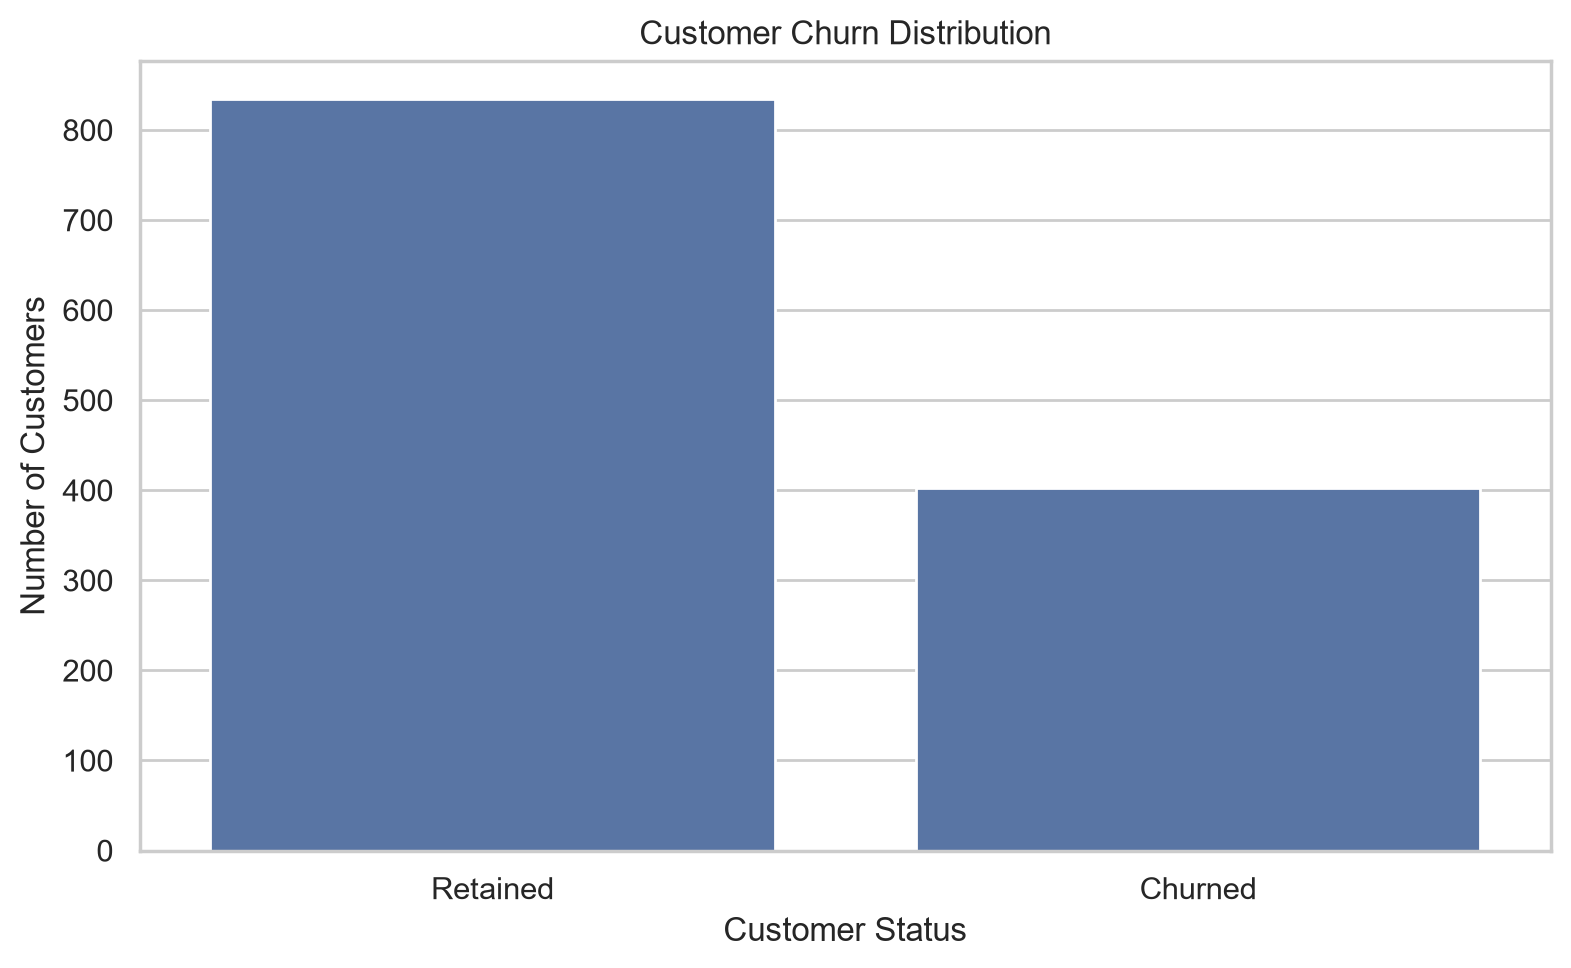


Churn By Contract


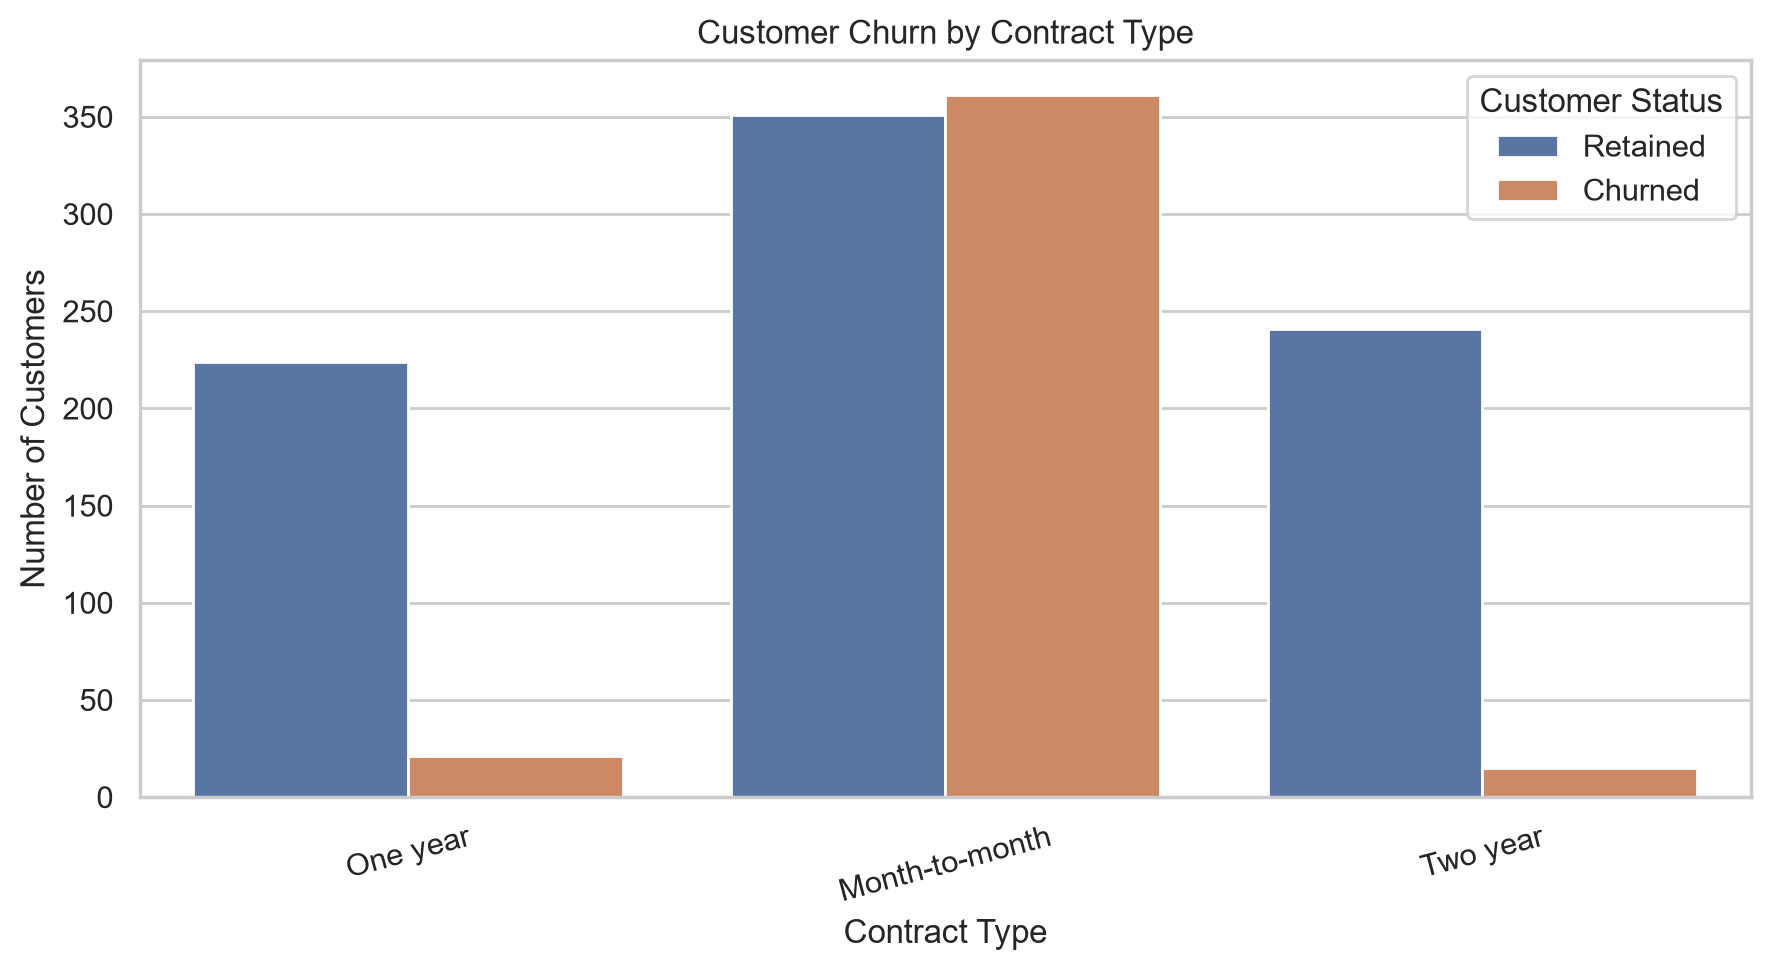


Churn By Internet Service


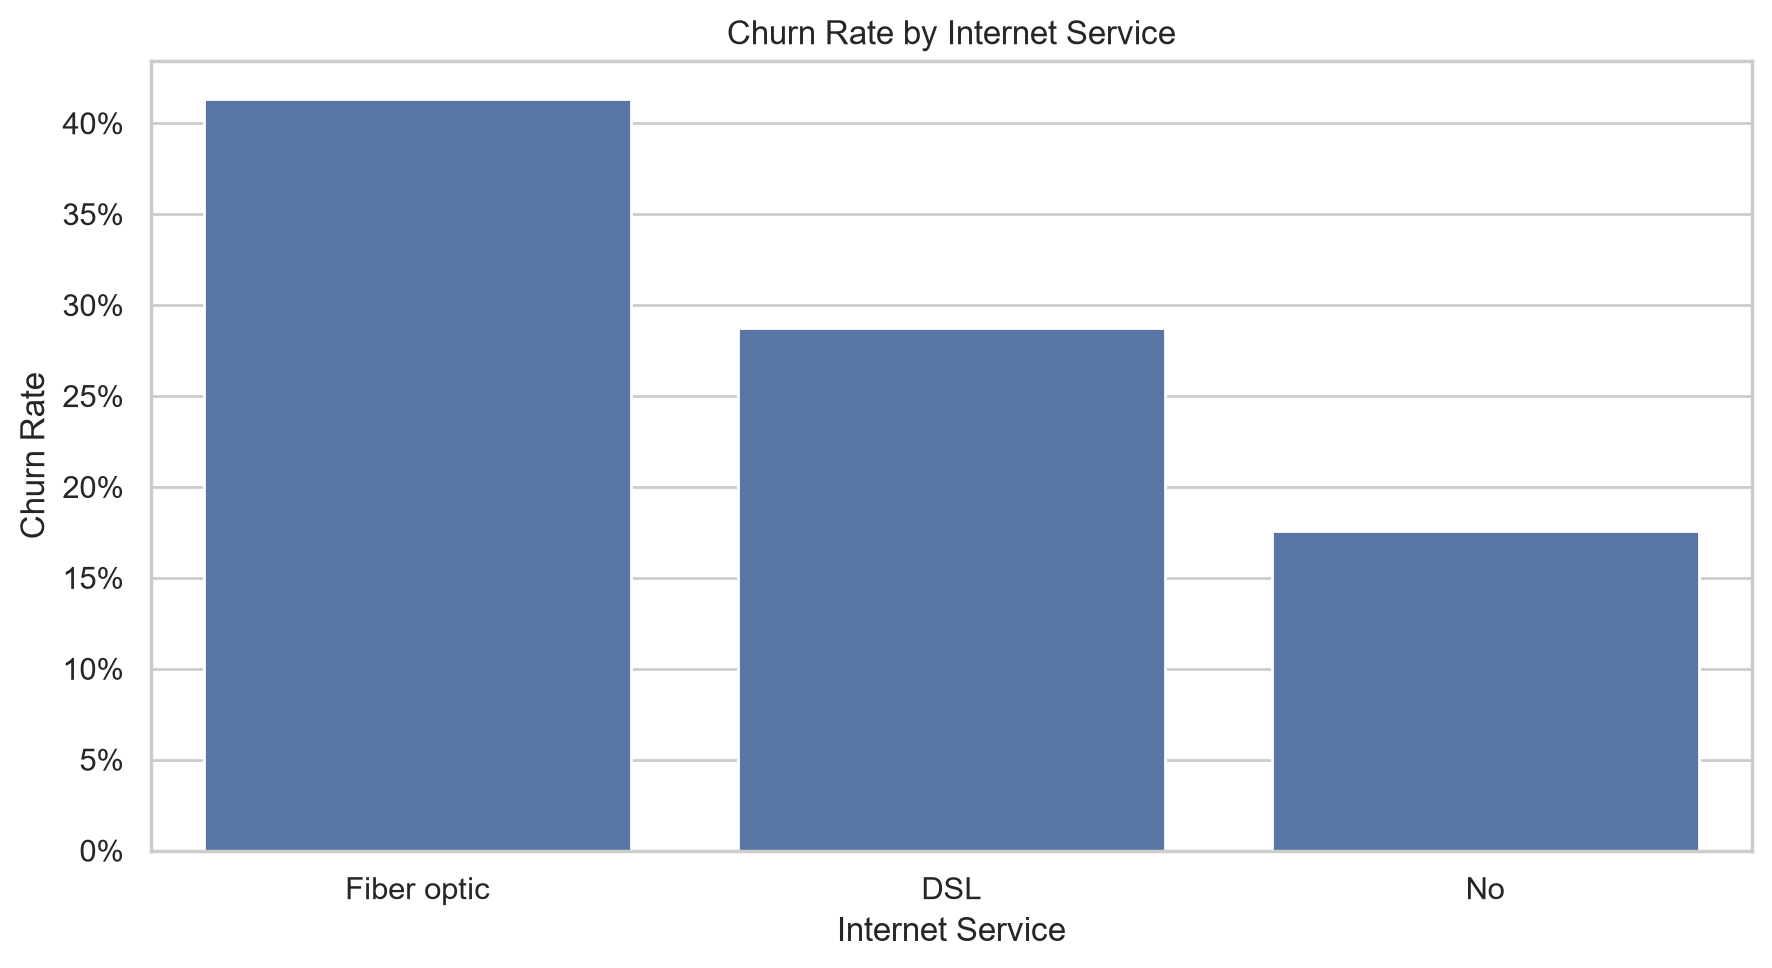


Monthly Charges Vs Churn


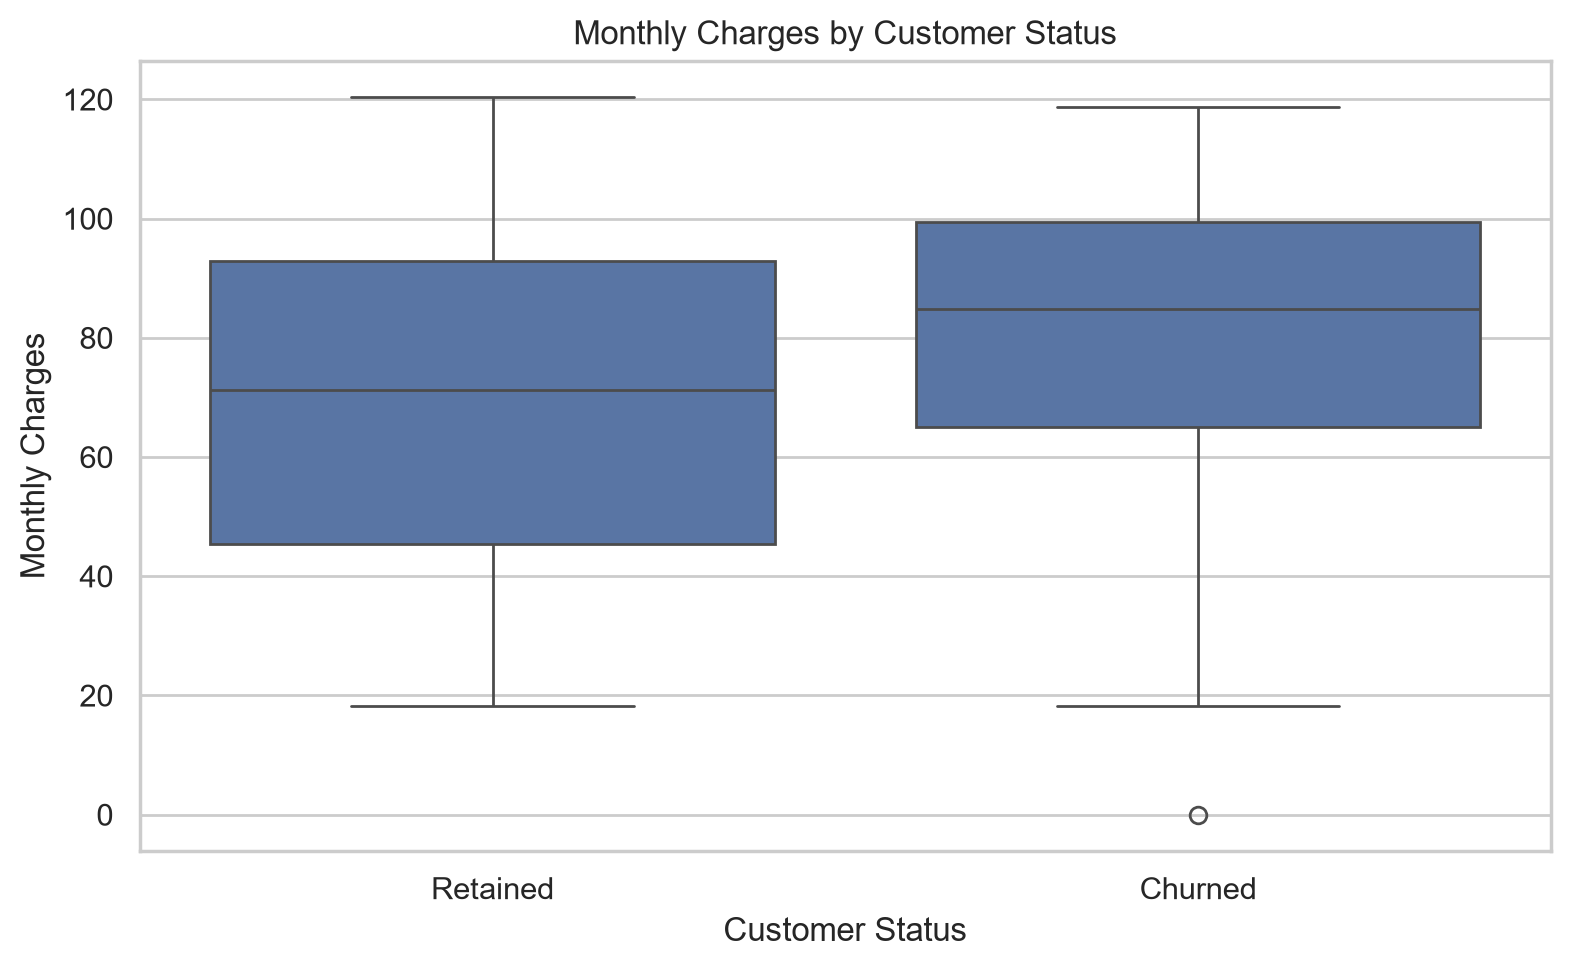


Tenure Vs Churn


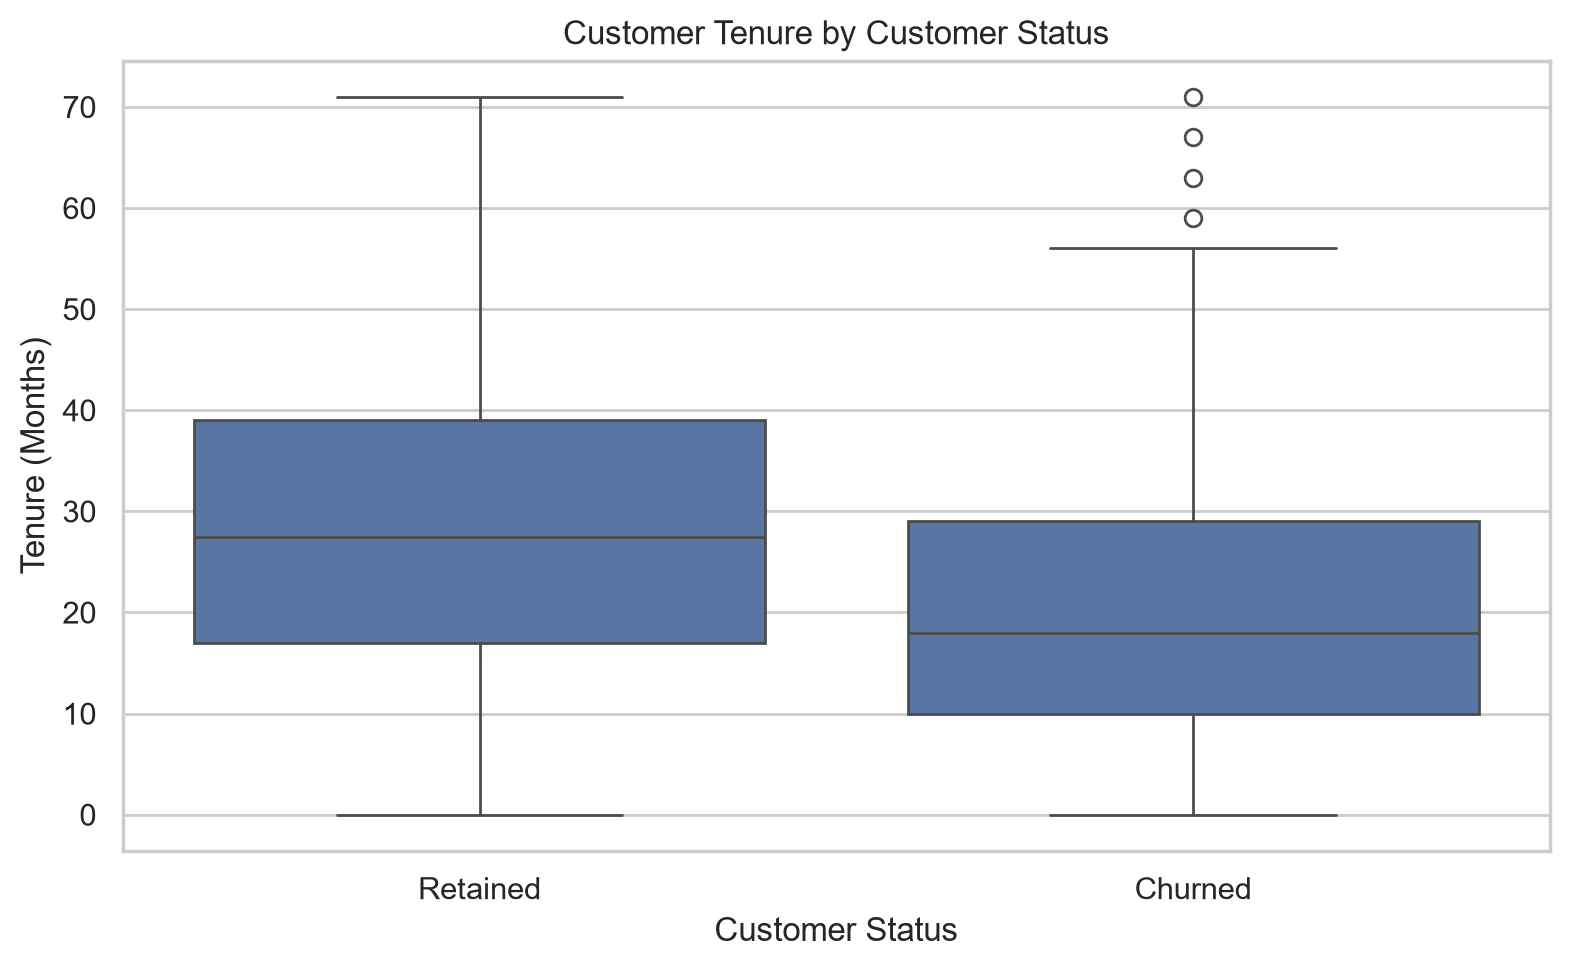

In [23]:

from IPython.display import display, Image

for filename in expected_plots:
    plot_path = PLOTS_DIR / filename

    print("\n" + filename.replace(".png", "").replace("_", " ").title())
    display(Image(filename=str(plot_path)))


## EDA Findings and Business Insights

1. **Churn Distribution:** Out of 1,238 customers with known churn labels, 403 customers churned (32.55%) and 835 remained (67.45%).

2. **Contract Type:** Month-to-month customers had the highest observed churn rate at approximately 50.7%. Flexible contracts may be associated with higher customer turnover.

3. **Internet Service:** Fiber-optic customers had the highest observed churn rate at approximately 41.4%. This segment may benefit from further investigation into service quality, pricing, and customer experience.

4. **Monthly Charges:** Churned customers had a median monthly charge of 84.80, compared with 71.27 for retained customers. Higher charges were associated with churn in this dataset.

5. **Customer Tenure:** Churned customers had a median tenure of 18 months, compared with 27.5 months for retained customers. Shorter tenure was associated with higher churn.

**Conclusion:** Contract type, internet service, monthly charges, and tenure show useful associations with customer churn. These findings describe patterns in the dataset and do not establish causation.

In [24]:

# Verify engineered features in the existing modeling dataset

MODELING_FILE = BASE_DIR / "data" / "processed" / "telecom_churn_modeling.csv"

model_df = pd.read_csv(MODELING_FILE)

print("Modeling dataset shape:", model_df.shape)
print("\nAvailable columns:")
print(model_df.columns.tolist())

expected_features = [
    "customer_risk_signals",
    "calculated_monthly_charge"
]

print("\nEngineered feature verification:")
for feature in expected_features:
    print(f"{feature}: {'FOUND' if feature in model_df.columns else 'MISSING'}")

if all(feature in model_df.columns for feature in expected_features):
    display(model_df[expected_features].head())


Modeling dataset shape: (1238, 23)

Available columns:
['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'signup_date', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'tech_support', 'streaming_tv', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'avg_monthly_gb', 'support_calls', 'late_payments', 'customer_satisfaction', 'churn']

Engineered feature verification:
customer_risk_signals: MISSING
calculated_monthly_charge: MISSING


In [41]:

# REQUIREMENT 9: Feature Engineering
# Work on a separate copy; preserve the original CSV.

feature_df = model_df.copy()

# Feature 1: Estimated average monthly charge
# Avoid division by zero and leave unavailable values missing.
feature_df["calculated_monthly_charge"] = np.nan

valid_tenure = feature_df["tenure_months"] > 0

total_charges = pd.to_numeric(
    feature_df["total_charges"],
    errors="coerce"
)

tenure_months = pd.to_numeric(
    feature_df["tenure_months"],
    errors="coerce"
)

feature_df.loc[valid_tenure, "calculated_monthly_charge"] = (
    total_charges.loc[valid_tenure]
    / tenure_months.loc[valid_tenure]
)

# Feature 2: Customer risk signals
# Keep the definition consistent with train_model.py and app.py.
# It is the sum of support calls and late payments.
feature_df["customer_risk_signals"] = (
    pd.to_numeric(feature_df["support_calls"], errors="coerce")
    + pd.to_numeric(feature_df["late_payments"], errors="coerce")
)

# Display the engineered features.
print("New features created:")

display(
    feature_df[
        [
            "calculated_monthly_charge",
            "customer_risk_signals"
        ]
    ].head()
)

# Verify that both engineered features exist.
print("\nEngineered feature verification:")

for col in [
    "calculated_monthly_charge",
    "customer_risk_signals"
]:
    print(f"{col}: {'FOUND' if col in feature_df.columns else 'MISSING'}")

print("\nFeature engineering completed.")


New features created:


,calculated_monthly_charge,customer_risk_signals
0,94.368293,2.0
1,64.748947,6.0
2,37.946562,2.0
3,NaN,2.0
4,71.287500,NaN



Engineered feature verification:
calculated_monthly_charge: FOUND
customer_risk_signals: FOUND

Feature engineering completed.


## Feature Engineering

Two additional features were created to enrich the customer churn dataset.

1. **calculated_monthly_charge:** Calculated by dividing `total_charges` by `tenure_months` for customers with tenure greater than zero. If tenure is zero or the required values are missing, the feature remains missing and will be handled during preprocessing.

2. **customer_risk_signals:** A count of four observed indicators: three or more support calls, at least one late payment, a month-to-month contract, and tenure of 12 months or less. Each indicator contributes one point when its condition is met.

These are derived analytical features, not proven causes of churn. Missing input values require careful handling so that the risk count is not interpreted as definitive evidence of low risk.

In [26]:

from pathlib import Path

training_script = BASE_DIR / "train_model.py"

print("Training script exists:", training_script.exists())

if training_script.exists():
    print("\n--- train_model.py ---\n")
    print(training_script.read_text(encoding="utf-8"))
else:
    print("Check BASE_DIR:", BASE_DIR)
    print("Available Python files:")
    print([p.name for p in BASE_DIR.glob("*.py")])


Training script exists: True

--- train_model.py ---


# train_model.py
# Telecom Customer Churn Prediction
# Baseline models with leakage-safe preprocessing

from pathlib import Path
import warnings

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore")

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

BASE_DIR = Path(__file__).resolve(

In [27]:

import re

script_text = training_script.read_text(encoding="utf-8")
script_lines = script_text.splitlines()

keywords = [
    "train_test_split",
    "ColumnTransformer",
    "Pipeline(",
    "SimpleImputer",
    "StandardScaler",
    "OneHotEncoder",
    "stratify=",
    "numeric_features",
    "categorical_features",
    "drop(",
    "target",
]

for i, line in enumerate(script_lines):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        start = max(0, i - 2)
        end = min(len(script_lines), i + 4)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {script_lines[j]}")



--- Lines 10-15 ---
10: import numpy as np
11: 
12: from sklearn.model_selection import train_test_split
13: from sklearn.compose import ColumnTransformer
14: from sklearn.pipeline import Pipeline
15: from sklearn.preprocessing import OneHotEncoder, StandardScaler

--- Lines 11-16 ---
11: 
12: from sklearn.model_selection import train_test_split
13: from sklearn.compose import ColumnTransformer
14: from sklearn.pipeline import Pipeline
15: from sklearn.preprocessing import OneHotEncoder, StandardScaler
16: from sklearn.impute import SimpleImputer

--- Lines 13-18 ---
13: from sklearn.compose import ColumnTransformer
14: from sklearn.pipeline import Pipeline
15: from sklearn.preprocessing import OneHotEncoder, StandardScaler
16: from sklearn.impute import SimpleImputer
17: from sklearn.metrics import (
18:     accuracy_score,

--- Lines 14-19 ---
14: from sklearn.pipeline import Pipeline
15: from sklearn.preprocessing import OneHotEncoder, StandardScaler
16: from sklearn.impute import 

In [28]:

keywords = [
    "train_test_split",
    "ColumnTransformer",
    "SimpleImputer",
    "StandardScaler",
    "OneHotEncoder",
    "stratify=",
]

for keyword in keywords:
    print(f"{keyword}: {keyword in script_text}")


train_test_split: True
ColumnTransformer: True
SimpleImputer: True
StandardScaler: True
OneHotEncoder: True
stratify=: True


In [29]:

print("Dataset columns:")
print(model_df.columns.tolist())

print("\nTarget values:")
print(model_df["churn"].value_counts(dropna=False))

print("\nEngineered features:")
print("calculated_monthly_charge" in feature_df.columns)
print("customer_risk_signals" in feature_df.columns)


Dataset columns:
['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'signup_date', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'tech_support', 'streaming_tv', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'avg_monthly_gb', 'support_calls', 'late_payments', 'customer_satisfaction', 'churn']

Target values:
churn
0    835
1    403
Name: count, dtype: int64

Engineered features:
True
True


In [30]:

from sklearn.model_selection import train_test_split

# Separate target from input features
X = feature_df.drop(columns=["churn", "customer_id", "signup_date"])
y = feature_df["churn"].astype(int)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (990, 22)
Testing features: (248, 22)
Numeric features: 9
Categorical features: 13

Training churn distribution:
churn
0    0.675
1    0.325
Name: proportion, dtype: float64

Testing churn distribution:
churn
0    0.673
1    0.327
Name: proportion, dtype: float64


In [31]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting on it
X_test_processed = preprocessor.transform(X_test)

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)
print("Preprocessing fitted on training data only.")
print("Missing values remaining in training matrix:",
      __import__("numpy").isnan(X_train_processed.data).sum()
      if hasattr(X_train_processed, "data")
      else __import__("numpy").isnan(X_train_processed).sum())


Training matrix shape: (990, 46)
Testing matrix shape: (248, 46)
Preprocessing fitted on training data only.
Missing values remaining in training matrix: 0


In [32]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

# Add XGBoost if it is installed
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed; other baseline models will run.")

results = []
baseline_pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    baseline_pipelines[name] = pipeline

baseline_results = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

# Add XGBoost if it is installed
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed; other baseline models will run.")

results = []
baseline_pipelines = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    baseline_pipelines[name] = pipeline

baseline_results = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7581,0.6479,0.5679,0.6053,0.7885
1,Logistic Regression,0.7500,0.6610,0.4815,0.5571,0.8101
2,Decision Tree,0.7056,0.5513,0.5309,0.5409,0.6606
3,Random Forest,0.7379,0.6481,0.4321,0.5185,0.8066


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7581,0.6479,0.5679,0.6053,0.7885
1,Logistic Regression,0.7500,0.6610,0.4815,0.5571,0.8101
2,Decision Tree,0.7056,0.5513,0.5309,0.5409,0.6606
3,Random Forest,0.7379,0.6481,0.4321,0.5185,0.8066


In [33]:

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    REPORTS_DIR / "baseline_model_comparison_notebook.csv",
    index=False
)

print("Baseline comparison saved successfully.")
print(REPORTS_DIR / "baseline_model_comparison_notebook.csv")


Baseline comparison saved successfully.
c:\Users\rabya\OneDrive\Documents\telecom-churn-prediction\reports\baseline_model_comparison_notebook.csv


In [34]:

print("XGBoost available:", "XGBoost" in baseline_pipelines)
print("Random Forest available:", "Random Forest" in baseline_pipelines)
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)


XGBoost available: True
Random Forest available: True
Training data: (990, 22)
Test data: (248, 22)


In [35]:

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest tuning
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_params,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Random Forest best CV F1:", round(rf_search.best_score_, 4))
print("Random Forest best parameters:")
print(rf_search.best_params_)

# XGBoost tuning
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("\nXGBoost best CV F1:", round(xgb_search.best_score_, 4))
print("XGBoost best parameters:")
print(xgb_search.best_params_)


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Random Forest best CV F1: 0.615
Random Forest best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 20}
Fitting 5 folds for each of 12 candidates, totalling 60 fits

XGBoost best CV F1: 0.623
XGBoost best parameters:
{'model__subsample': 1.0, 'model__n_estimators': 100, 'model__min_child_weight': 3, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


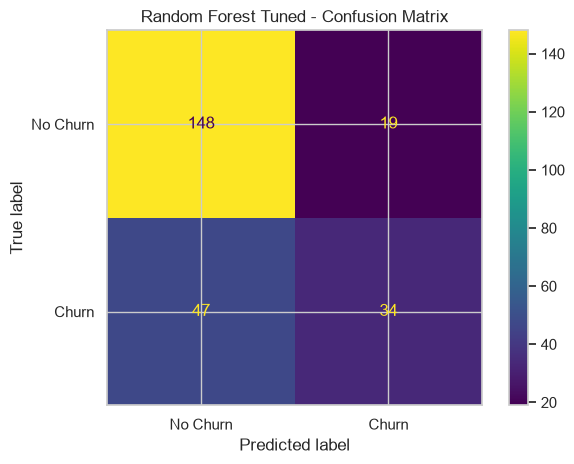

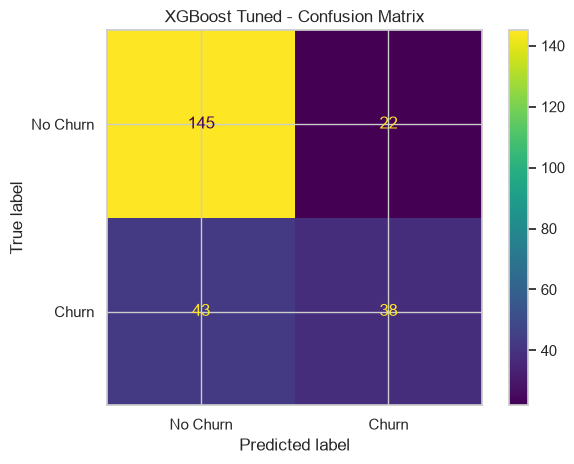

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost Tuned,0.7379,0.6333,0.4691,0.5390,0.8032
1,Random Forest Tuned,0.7339,0.6415,0.4198,0.5075,0.7963


Tuned comparison and confusion matrices saved.


In [36]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

tuned_models = {
    "Random Forest Tuned": rf_search.best_estimator_,
    "XGBoost Tuned": xgb_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    cm = confusion_matrix(y_test, predictions)

    display_labels = ["No Churn", "Churn"]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    )
    disp.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_") + "_confusion_matrix.png"
    plt.savefig(PLOTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

tuned_results = pd.DataFrame(tuned_results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(tuned_results.round(4))

tuned_results.to_csv(
    REPORTS_DIR / "tuned_model_comparison_notebook.csv",
    index=False
)

print("Tuned comparison and confusion matrices saved.")


In [37]:

all_results = pd.concat(
    [baseline_results, tuned_results],
    ignore_index=True
)

all_results = all_results.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(all_results.round(4))

all_results.to_csv(
    REPORTS_DIR / "all_models_comparison_notebook.csv",
    index=False
)

print("\nBest model by test F1:")
display(all_results.head(1))
print("Full comparison saved.")


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7581,0.6479,0.5679,0.6053,0.7885
1,Logistic Regression,0.7500,0.6610,0.4815,0.5571,0.8101
2,Decision Tree,0.7056,0.5513,0.5309,0.5409,0.6606
3,XGBoost Tuned,0.7379,0.6333,0.4691,0.5390,0.8032
4,Random Forest,0.7379,0.6481,0.4321,0.5185,0.8066
5,Random Forest Tuned,0.7339,0.6415,0.4198,0.5075,0.7963



Best model by test F1:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.758065,0.647887,0.567901,0.605263,0.788497


Full comparison saved.


In [38]:

import joblib

# Select the best model based on test-set F1
best_model_name = "XGBoost"
best_model = baseline_pipelines[best_model_name]

MODELS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "telecom_churn_best_model.joblib"

joblib.dump(best_model, model_path)

print("Selected model:", best_model_name)
print("Saved model:", model_path)
print("File exists:", model_path.exists())


Selected model: XGBoost
Saved model: c:\Users\rabya\OneDrive\Documents\telecom-churn-prediction\models\telecom_churn_best_model.joblib
File exists: True


In [39]:

import joblib
import numpy as np

# Reload the saved model
loaded_model = joblib.load(model_path)

# Generate predictions on test data
test_predictions = loaded_model.predict(X_test)

print("Model loaded successfully:", loaded_model is not None)
print("Predictions generated:", len(test_predictions))
print("Prediction examples:", test_predictions[:10])
print("Prediction classes:", np.unique(test_predictions))


Model loaded successfully: True
Predictions generated: 248
Prediction examples: [0 1 0 1 1 1 0 0 0 0]
Prediction classes: [0 1]


In [40]:

# Take one customer from the held-out test data
sample_customer = X_test.iloc[[0]].copy()

# Predict churn class and churn probability
predicted_class = loaded_model.predict(sample_customer)[0]
churn_probability = loaded_model.predict_proba(sample_customer)[0, 1]

print("Predicted result:", "Churn" if predicted_class == 1 else "No Churn")
print(f"Estimated churn probability: {churn_probability:.2%}")


Predicted result: No Churn
Estimated churn probability: 0.55%
